# Información del dataset

**Problema:** predecir el precio de venta de una propiedad en Pakistán a partir de sus características (regresión supervisada; target: `price`).

**Fuente:** anuncios de zameen.com en cinco ciudades (Karachi, Lahore, Islamabad, Rawalpindi y Faisalabad). Archivo `Entities.csv`, que se coloca en `data/bronze/` y no se sube al repositorio.

Este notebook describe los datos **tal y como llegan**, sin modificarlos. Las correcciones se hacen en `data_cleaning_pre_train_test_split.ipynb`.

## 1. Carga de datos

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("../data/bronze/Entities.csv", index_col=0)

## 2. Primer vistazo

Los 30 primeros registros. Las columnas `agency` y `agent` tienen huecos y `page_url` es larga y única por anuncio.

In [3]:
df.head(30)

,property_id,location_id,page_url,property_type,price,location,city,province_name,latitude,longitude,baths,purpose,bedrooms,date_added,agency,agent,Total_Area
0,237062,3325,https://www.zameen.com/Property/g_10_g_10_2_gr...,Flat,10000000,G-10,Islamabad,Islamabad Capital,33.679890,73.012640,2,For Sale,2,2/4/2019,NaN,NaN,1089.004
1,346905,3236,https://www.zameen.com/Property/e_11_2_service...,Flat,6900000,E-11,Islamabad,Islamabad Capital,33.700993,72.971492,3,For Sale,3,5/4/2019,NaN,NaN,15246.056
2,386513,764,https://www.zameen.com/Property/islamabad_g_15...,House,16500000,G-15,Islamabad,Islamabad Capital,33.631486,72.926559,6,For Sale,5,7/17/2019,NaN,NaN,2178.008
3,656161,340,https://www.zameen.com/Property/islamabad_bani...,House,43500000,Bani Gala,Islamabad,Islamabad Capital,33.707573,73.151199,4,For Sale,4,4/5/2019,NaN,NaN,10890.000
4,841645,3226,https://www.zameen.com/Property/dha_valley_dha...,House,7000000,DHA Defence,Islamabad,Islamabad Capital,33.492591,73.301339,3,For Sale,3,7/10/2019,Easy Property,Muhammad Junaid Ceo Muhammad Shahid Director,2178.008
5,850762,3390,https://www.zameen.com/Property/ghauri_town_gh...,House,34500000,Ghauri Town,Islamabad,Islamabad Capital,33.623947,73.126588,8,For Sale,8,4/5/2019,NaN,NaN,87120.000
6,937975,445,https://www.zameen.com/Property/islamabad_kora...,House,27000000,Korang Town,Islamabad,Islamabad Capital,33.579034,73.139591,8,For Sale,8,1/4/2019,NaN,NaN,5445.000
7,1258636,3241,https://www.zameen.com/Property/e_11_e_11_4_ap...,Flat,7800000,E-11,Islamabad,Islamabad Capital,33.698244,72.984238,2,For Sale,2,5/5/2019,Ettemad Enterprises,Balqiaz Marwat,16879.562
8,1402466,376,https://www.zameen.com/Property/dha_defence_dh...,House,50000000,DHA Defence,Islamabad,Islamabad Capital,33.540894,73.095732,7,For Sale,7,10/19/2018,Easy Property,Muhammad Junaid Ceo Muhammad Shahid Director,5445.000
9,1418706,3282,https://www.zameen.com/Property/f_11_f_11_1_f_...,Penthouse,40000000,F-11,Islamabad,Islamabad Capital,33.679211,72.988787,5,For Sale,5,6/27/2019,Crown Associate,Abrar Ahmed,5445.000


## 3. Dimensiones, tipos y valores nulos

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 168446 entries, 0 to 168445
Data columns (total 17 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   property_id    168446 non-null  int64  
 1   location_id    168446 non-null  int64  
 2   page_url       168446 non-null  str    
 3   property_type  168446 non-null  str    
 4   price          168446 non-null  int64  
 5   location       168446 non-null  str    
 6   city           168446 non-null  str    
 7   province_name  168446 non-null  str    
 8   latitude       168446 non-null  float64
 9   longitude      168446 non-null  float64
 10  baths          168446 non-null  int64  
 11  purpose        168446 non-null  str    
 12  bedrooms       168446 non-null  int64  
 13  date_added     168446 non-null  str    
 14  agency         124375 non-null  str    
 15  agent          124374 non-null  str    
 16  Total_Area     168446 non-null  float64
dtypes: float64(3), int64(5), str(9)
memory u

El dataset tiene **168.446 anuncios y 17 columnas** (sin contar el índice). Los únicos nulos están en `agency` y `agent` (26,2 % cada una).

## 4. Estadísticos descriptivos

In [5]:
df.describe()

,property_id,location_id,price,latitude,longitude,baths,bedrooms,Total_Area
count,1.684460e+05,168446.000000,1.684460e+05,168446.000000,168446.000000,168446.000000,168446.000000,1.684460e+05
mean,1.559626e+07,4375.936395,1.776576e+07,29.859519,71.239804,2.874227,3.179422,1.394239e+04
std,2.251207e+06,3776.561581,3.531003e+07,3.807870,3.133042,2.463400,1.971401,8.623647e+05
min,8.657500e+04,1.000000,0.000000e+00,11.052446,25.906027,0.000000,0.000000,0.000000e+00
25%,1.488320e+07,1058.000000,1.750000e+05,24.948536,67.130363,0.000000,2.000000,1.905757e+03
50%,1.665851e+07,3286.000000,8.500000e+06,31.459784,73.056182,3.000000,3.000000,4.356016e+03
75%,1.708662e+07,7220.000000,1.950000e+07,33.560887,73.259870,4.000000,4.000000,1.197904e+04
max,1.735772e+07,14220.000000,2.000000e+09,73.184088,80.161430,403.000000,68.000000,3.387988e+08


El `describe()` ya avisa de varios problemas:

- `price` tiene un mínimo de 0 y un máximo de 2.000 millones de rupias.
- `baths` llega a 403 y `bedrooms` a 68.
- `Total_Area` tiene un mínimo de 0 y un máximo de 3,4·10⁸ (en pies cuadrados).
- `latitude` llega a 73 y `longitude` baja a 25,9, valores que no corresponden a Pakistán.
- La media de `price` y `Total_Area` es muy superior a la mediana: distribuciones con cola larga a la derecha.

## 5. Diccionario de variables

El `dtype` de pandas no es el tipo real de la variable, por eso se indica el tipo real y el uso previsto.

| Variable | Descripción | Tipo real | dtype | Uso previsto |
|---|---|---|---|---|
| `property_id` | Identificador del anuncio | Identificador | int64 | Descartar |
| `location_id` | Identificador de la zona | Identificador (redundante con `location`) | int64 | Descartar |
| `page_url` | Enlace al anuncio | Texto único | object | Descartar |
| `property_type` | Tipo de inmueble (House, Flat, Upper/Lower Portion, Room, Penthouse, Farm House) | Cualitativa nominal | object | Predictor (codificar) |
| `price` | Precio publicado, en rupias (PKR) | Cuantitativa continua | int64 | **Target** (se pasa a euros) |
| `location` | Barrio o zona | Cualitativa nominal de alta cardinalidad | object | Predictor mediante el precio medio por barrio (después del split) |
| `city` | Ciudad | Cualitativa nominal | object | Predictor (codificar) |
| `province_name` | Provincia | Cualitativa nominal (determinada por `city`) | object | Redundante con `city` |
| `latitude`, `longitude` | Coordenadas del anuncio | Cuantitativa continua | float64 | Se resumen en `dist_centro_km` y se descartan |
| `baths` | Número de baños | Cuantitativa discreta | int64 | Predictor |
| `bedrooms` | Número de habitaciones | Cuantitativa discreta | int64 | Predictor |
| `purpose` | Venta o alquiler | Cualitativa nominal (binaria) | object | Filtrar (`For Sale`) y descartar |
| `date_added` | Fecha de publicación | Fecha | object | Convertir a `datetime`; uso por decidir |
| `agency`, `agent` | Agencia y agente | Cualitativa nominal de alta cardinalidad | object | Descartar (26 % de nulos) |
| `Total_Area` | Superficie total, en pies cuadrados | Cuantitativa continua | float64 | Predictor (se pasa a m²) |

## 6. Calidad de los datos

### 6.1 Valores nulos

In [6]:
nulos = df.isna().sum().to_frame("nulos")
nulos["% sobre el total"] = (nulos["nulos"] / len(df) * 100).round(1)
nulos[nulos["nulos"] > 0]

,nulos,% sobre el total
agency,44071,26.2
agent,44072,26.2


Solo `agency` y `agent`, y las vamos a descartar, así que **no hace falta imputar nada**.

### 6.2 Duplicados

In [7]:
ids = ["property_id", "location_id", "page_url", "agency", "agent"]
dup = df.drop(columns=ids).duplicated().sum()
print(f"Anuncios repetidos (ignorando identificadores): {dup} ({dup / len(df):.1%})")
print("property_id repetidos:", df["property_id"].duplicated().sum())
print("page_url repetidas:   ", df["page_url"].duplicated().sum())

Anuncios repetidos (ignorando identificadores): 20489 (12.2%)
property_id repetidos: 0
page_url repetidas:    0


El identificador y la URL no se repiten nunca, pero hay **20.489 anuncios idénticos en todo lo demás** (12,2 %): el mismo inmueble publicado varias veces con distinto id. Si no se quitan, el modelo vería el mismo dato en train y en test.

**Acción:** eliminar duplicados después de borrar las columnas de identificación (ya hecho en la limpieza previa).

### 6.3 Ceros que podrían ser datos ausentes

In [8]:
cols = ["price", "Total_Area", "baths", "bedrooms"]
ceros = pd.DataFrame({
    "ceros": [(df[c] == 0).sum() for c in cols],
    "%": [round((df[c] == 0).mean() * 100, 1) for c in cols],
}, index=cols)
ceros

,ceros,%
price,3,0.0
Total_Area,12,0.0
baths,42382,25.2
bedrooms,22704,13.5


Hay un 25,2 % de anuncios con 0 baños y un 13,5 % con 0 habitaciones. Muchas casas con 0 baños y 4 habitaciones no son reales: el cero parece ser un dato no rellenado. En `price` y `Total_Area` los ceros son pocos (3 y 12).

**Acción:** eliminar las combinaciones incoherentes de habitaciones y baños (hecho en la limpieza previa) y las superficies a 0 (tercera vuelta de la limpieza previa).

### 6.4 Valores imposibles o fuera de rango

In [9]:
imposibles = pd.Series({
    "baths >= 7": (df["baths"] >= 7).sum(),
    "bedrooms >= 7": (df["bedrooms"] >= 7).sum(),
    "baths máximo": df["baths"].max(),
    "bedrooms máximo": df["bedrooms"].max(),
    "Total_Area máxima (pies²)": df["Total_Area"].max(),
})
display(imposibles)

fuera = ~df["latitude"].between(23.5, 37.1) | ~df["longitude"].between(60.8, 77.9)
print(f"\nAnuncios con coordenadas fuera de Pakistán: {fuera.sum()}")
df[fuera][["city", "location", "latitude", "longitude"]].head()

baths >= 7                        8993.0
bedrooms >= 7                     6292.0
baths máximo                       403.0
bedrooms máximo                     68.0
Total_Area máxima (pies²)    338798790.0
dtype: float64


Anuncios con coordenadas fuera de Pakistán: 10


,city,location,latitude,longitude
2528,Karachi,North Karachi,72.610337,57.839654
3279,Islamabad,G-11,68.273802,51.871316
4006,Rawalpindi,Adiala Road,63.350414,39.176150
5581,Islamabad,F-6,47.656480,80.161430
5867,Rawalpindi,Range Road,68.435573,57.070567


Hay valores imposibles en `baths`, `bedrooms` y `Total_Area`, y coordenadas fuera del país. En las ciudades, algunas coordenadas no están fuera de Pakistán pero sí lejos de su ciudad, por eso la limpieza previa mide la distancia al centro de la ciudad y descarta lo que queda a más de 100 km.

**Acción:** filtros por rango en la limpieza previa, que se detallan allí.

### 6.5 Variables categóricas

In [10]:
for c in ["purpose", "property_type", "city"]:
    print(df[c].value_counts().to_frame("anuncios").assign(**{"%": lambda d: (d["anuncios"] / len(df) * 100).round(1)}))
    print()
pd.crosstab(df["city"], df["province_name"])

          anuncios     %
purpose                 
For Sale    120655  71.6
For Rent     47791  28.4

               anuncios     %
property_type                
House            105468  62.6
Flat              38238  22.7
Upper Portion     13774   8.2
Lower Portion      9229   5.5
Room                685   0.4
Farm House          657   0.4
Penthouse           395   0.2

            anuncios     %
city                      
Karachi        60484  35.9
Lahore         41427  24.6
Islamabad      37426  22.2
Rawalpindi     20976  12.5
Faisalabad      8133   4.8



province_name,Islamabad Capital,Punjab,Sindh
city,,,
Faisalabad,0,8133,0
Islamabad,37426,0,0
Karachi,0,0,60484
Lahore,0,41427,0
Rawalpindi,0,20976,0


- `purpose` mezcla ventas (71,6 %) y alquileres (28,4 %), con precios de escalas distintas: **hay que quedarse solo con las ventas**.
- `property_type` está dominada por `House` (62,6 %); `Penthouse`, `Farm House` y `Room` son muy raras (menos del 0,5 % cada una).
- `province_name` está determinada por `city` (cada ciudad pertenece a una sola provincia), así que aporta poca información propia.
- `city` está desequilibrada: Karachi y Lahore suman el 60 %, Faisalabad el 4,8 %.

### 6.6 Fechas y variable `location`

In [11]:
fechas = pd.to_datetime(df["date_added"])
print("Rango de fechas:", fechas.min().date(), "->", fechas.max().date())

print("\nValores distintos de location:", df["location"].nunique())
print("Combinaciones (city, location):", df.groupby(["city", "location"]).ngroups)
n_ciudades = df.groupby("location")["city"].nunique()
print("Nombres de location que aparecen en más de una ciudad:", (n_ciudades > 1).sum())

Rango de fechas: 2018-08-05 -> 2019-07-18



Valores distintos de location: 1509
Combinaciones (city, location): 1590
Nombres de location que aparecen en más de una ciudad: 64


- Las fechas van de agosto de 2018 a julio de 2019 (menos de un año), así que no hay tendencia temporal larga. Por eso el tipo de cambio del 18/07/2019 (última fecha del dataset) es una aproximación razonable.
- `location` tiene más de 1.500 valores y 64 nombres se repiten en ciudades distintas. **Hay que trabajar con la pareja (`city`, `location`)** y no solo con el nombre.

### 6.7 La variable objetivo

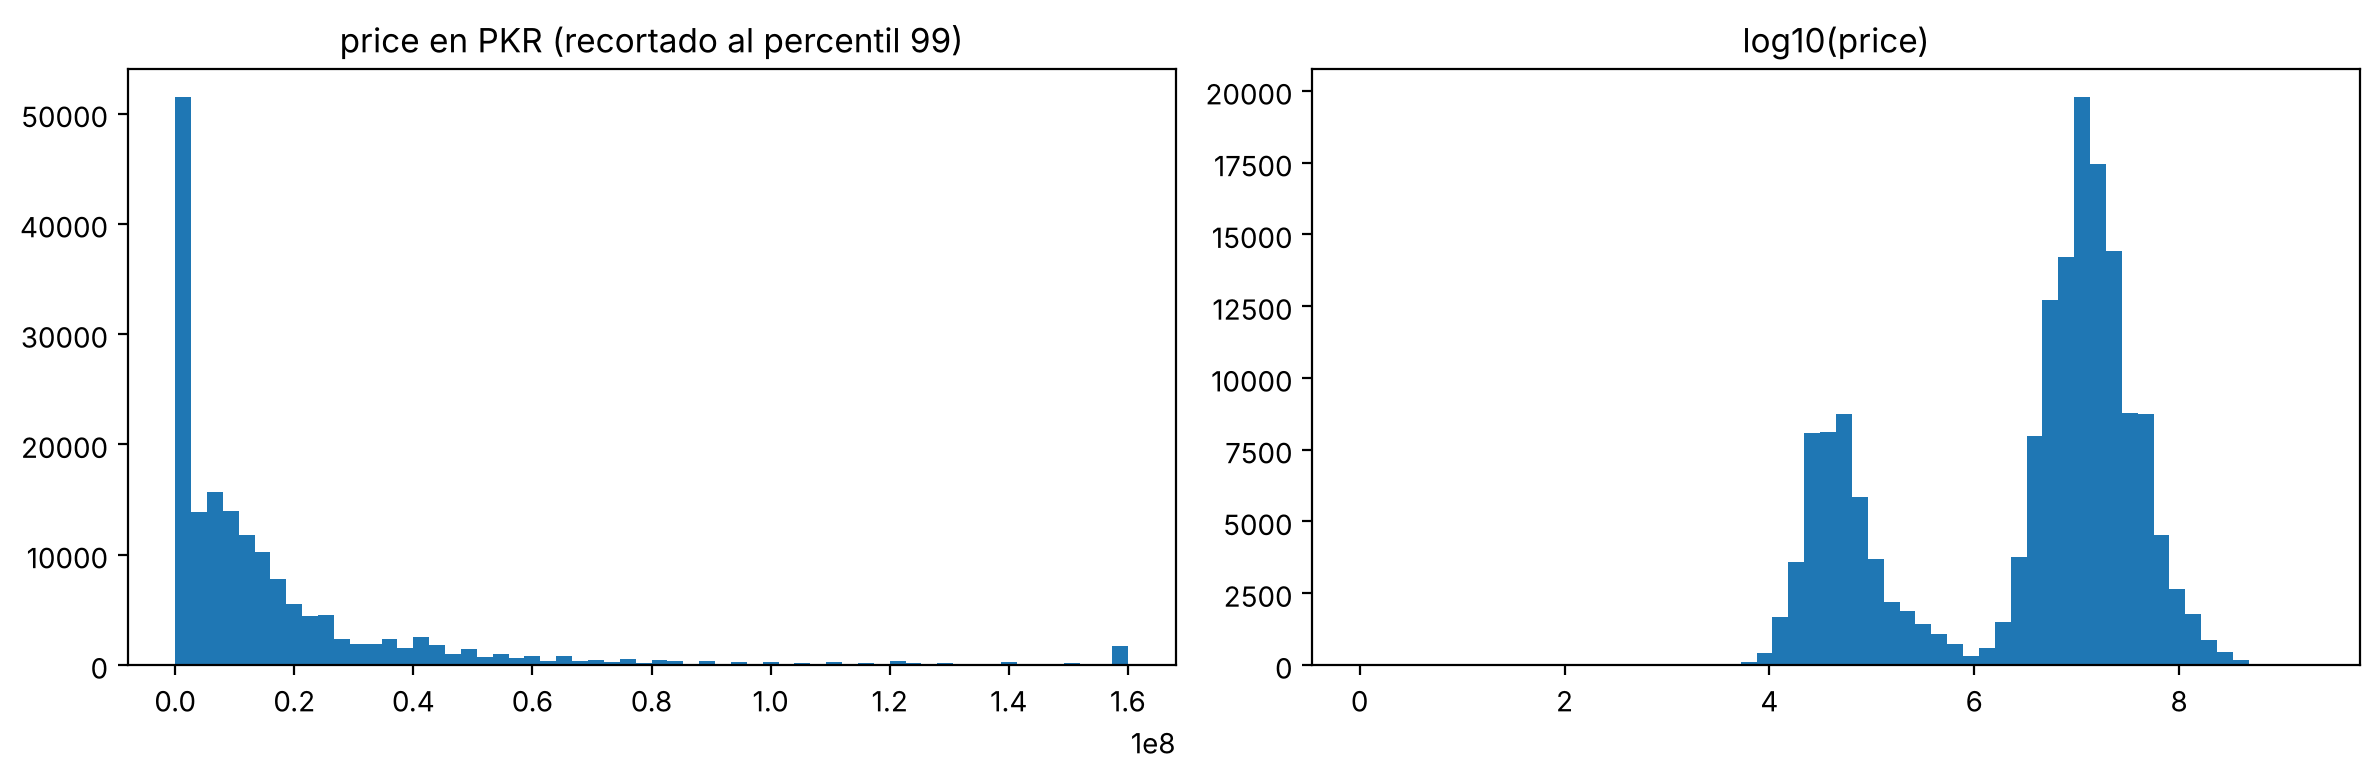

Asimetría de price: 9.35


In [12]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["price"].clip(upper=df["price"].quantile(0.99)), bins=60)
axes[0].set_title("price en PKR (recortado al percentil 99)")
axes[1].hist(np.log10(df["price"].clip(lower=1)), bins=60)
axes[1].set_title("log10(price)")
plt.tight_layout()
plt.show()

print(f"Asimetría de price: {df['price'].skew():.2f}")

`price` tiene una cola muy larga a la derecha (asimetría 9,3) y se acerca mucho más a una distribución simétrica en escala logarítmica. **Acción:** valorar `log(price)` como target.

## 7. Conclusiones y acciones

| Hallazgo | Acción | Dónde |
|---|---|---|
| 20.489 anuncios repetidos (12,2 %) | Eliminar duplicados | Limpieza previa |
| `agency` y `agent` con 26 % de nulos y sin valor predictivo | Descartar | Limpieza previa |
| Identificadores y URL sin valor predictivo | Descartar | Limpieza previa |
| 25 % de los anuncios con 0 baños y 13,5 % con 0 habitaciones | Eliminar combinaciones incoherentes | Limpieza previa |
| Baños y habitaciones con valores imposibles (403 y 68) | Quedarnos con menos de 7 | Limpieza previa |
| Superficies y precios imposibles (0 y valores enormes) | Filtros por tipo de propiedad | Limpieza previa |
| Coordenadas fuera de rango | Crear `dist_centro_km` y quitar lo que queda a más de 100 km | Limpieza previa |
| Mezcla de ventas y alquileres | Quedarnos con `For Sale` | Limpieza previa |
| `price` y `Total_Area` en PKR y pies² | Pasar a euros y a m² | Limpieza previa |
| `location` con cardinalidad muy alta y nombres repetidos entre ciudades | Precio medio por (`city`, `location`) solo con train | Limpieza posterior al split |
| `price` muy asimétrica | Valorar `log(price)` | EDA y modelado |
